# DỰ ÁN DỰ ĐOÁN & PHÂN LOẠI NGUY CƠ NGHÈO ĐÓI TỈNH ĐẮK NÔNG
### Ứng dụng Mô hình XGBoost Classifier, Kỹ nghệ Đặc trưng Nâng cao & Phân tích Đóng góp SHAP

---

## 1. Bối cảnh & Mục tiêu Bài toán (Project Overview)

Tỉnh Đắk Nông nằm ở khu vực Tây Nguyên với đặc thù địa hình chia cắt, tỷ lệ đồng bào dân tộc thiểu số cao và sự phân hóa kinh tế mạnh mẽ giữa các vùng xã. 

Bộ dữ liệu nghiên cứu bao gồm **22.698 hộ gia đình** được khảo sát và chuẩn hóa qua các kỳ rà soát an sinh xã hội cấp cơ sở, với mục tiêu phân loại hộ vào 3 trạng thái:
* **Nhóm 0 (Bình thường / Đã thoát nghèo):** Hộ gia đình có thu nhập và điều kiện sống đạt chuẩn.
* **Nhóm 1 (Hộ nghèo):** Hộ thiếu hụt nghiêm trọng cả về thu nhập lẫn các dịch vụ xã hội cơ bản (y tế, giáo dục, nhà ở, nước sạch,...).
* **Nhóm 2 (Hộ cận nghèo):** Hộ gia đình nằm sát chuẩn nghèo, có nguy cơ tái nghèo rất cao khi gặp các cú sốc kinh tế hoặc biến cố y tế.

### Thách thức chính & Định hướng giải quyết:
1. **Mất cân bằng nhãn sâu sắc:** Nhóm 0 chỉ chiếm ~2.04% tổng số hộ, trong khi Nhóm 1 (~49.5%) và Nhóm 2 (~48.4%) chiếm đa số. Bài toán trọng tâm là **phân định chính xác giữa Hộ nghèo và Hộ cận nghèo**.
2. **Kỹ nghệ đặc trưng (Feature Engineering):** Bổ sung các chỉ số phản ánh cấu trúc kinh tế hộ (tỷ số phụ thuộc trên lao động, cờ dân tộc thiểu số, chủ hộ nữ đơn thân nuôi con, phân nhóm tuổi chủ hộ).
3. **Mã hóa địa lý chống Data Leakage:** Áp dụng **Smoothed Target Encoding** trên tỷ lệ hộ nghèo thật sự ($y=1$) cho từng địa bàn xã có hệ số làm mượt $m$-estimate trên tập Train.
4. **Tối ưu hóa mô hình XGBoost & Kiểm soát Overfitting:** Tinh chỉnh độ sâu (`max_depth=5`), tăng cường hàm phạt $L_1/L_2$ (`reg_alpha`, `reg_lambda`), kết hợp trọng số mẫu cân bằng (`sample_weights`).
5. **Giải thích mô hình chuyên sâu với SHAP:** Phân tích độ đóng góp của từng yếu tố, bóc tách cơ chế đẩy một gia đình vào lõi nghèo để đề xuất can thiệp chính sách.

In [7]:
%pip install -q xgboost shap scikit-learn pandas numpy matplotlib seaborn

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'd:\\CV\\ApplyInternVNA\\Intern\\.venv\\Lib\\site-packages\\scipy\\integrate\\_quadpack_py.py'
Check the permissions.



Note: you may need to restart the kernel to use updated packages.


In [8]:
# =====================================================================
# BƯỚC 1: KHAI BÁO THƯ VIỆN & CẤU HÌNH HỆ THỐNG
# =====================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb
import shap

warnings.filterwarnings('ignore')

# Cấu hình giao diện biểu đồ chuyên nghiệp
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
sns.set_palette("husl")

print("[*] Đã tải thành công các thư viện cần thiết!")

d:\CV\ApplyInternVNA\Intern\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] Đã tải thành công các thư viện cần thiết!


In [9]:
# =====================================================================
# BƯỚC 2: TẢI DỮ LIỆU LINH HOẠT & KIỂM TRA PHÂN PHỐI NHÃN
# =====================================================================

# Danh sách đường dẫn khả dĩ (local máy cá nhân, thư mục cha, hoặc Kaggle)
candidate_paths = [
    'DAK_NONG_ML_DATASET.csv',
    '../DAK_NONG_ML_DATASET.csv',
    '/kaggle/input/datasets/duykhnhphm/dak-nong/DAK_NONG_ML_DATASET.csv',
    '/kaggle/input/dak-nong/DAK_NONG_ML_DATASET.csv'
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), candidate_paths[0])
print(f"[*] Nạp dữ liệu từ: {data_path}")

df = pd.read_csv(data_path)
print(f"-> Kích thước tập dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")

# Thống kê phân phối nhãn mục tiêu
target_counts = df['PHAN_LOAI_HO'].value_counts().sort_index()
target_pcts = df['PHAN_LOAI_HO'].value_counts(normalize=True).sort_index() * 100

summary_target = pd.DataFrame({
    'Mã Nhãn': target_counts.index,
    'Trạng Thái Hộ': ['Bình Thường (0)', 'Hộ Nghèo (1)', 'Hộ Cận Nghèo (2)'],
    'Số Lượng (Hộ)': target_counts.values,
    'Tỷ Lệ (%)': target_pcts.round(2).values
})
print("--- PHÂN PHỐI NHÃN MỤC TIÊU ---")
print(summary_target.to_string(index=False))

# Kiểm tra dữ liệu khuyết
missing_count = df.isnull().sum().sum()
print(f"[*] Tổng số ô bị khuyết (NaN/Null): {missing_count} ô (Dữ liệu sạch 100%)")

[*] Nạp dữ liệu từ: ../DAK_NONG_ML_DATASET.csv
-> Kích thước tập dữ liệu: 22,698 dòng x 15 cột
--- PHÂN PHỐI NHÃN MỤC TIÊU ---
 Mã Nhãn    Trạng Thái Hộ  Số Lượng (Hộ)  Tỷ Lệ (%)
       0  Bình Thường (0)            464       2.04
       1     Hộ Nghèo (1)          11246      49.55
       2 Hộ Cận Nghèo (2)          10988      48.41
[*] Tổng số ô bị khuyết (NaN/Null): 0 ô (Dữ liệu sạch 100%)


### Nhận xét về Đặc điểm Dữ liệu & Thách thức Phân loại:
1. **Phân phối nhãn lệch mạnh:** Vì đây là tập dữ liệu thu thập từ cuộc khảo sát hộ nghèo/cận nghèo định kỳ của tỉnh, tỷ lệ Hộ nghèo (49.55%) và Hộ cận nghèo (48.41%) chiếm đến **97.96%**, trong khi Hộ bình thường chỉ chiếm **2.04%** (464 hộ).
2. **Nút thắt kỹ thuật:** Mô hình có thể dễ dàng tách biệt Class 0 khỏi {1, 2}. Tuy nhiên, **thách thức thực sự nằm ở việc phân biệt giữa Hộ nghèo (Class 1) và Hộ cận nghèo (Class 2)** do hai nhóm này có nhiều đặc điểm kinh tế - nhân khẩu học tương đồng. Cần có các đặc trưng tương tác sâu và mã hóa địa bàn chuẩn xác để mở khóa ranh giới này.

In [14]:
# =====================================================================
# BƯỚC 3: KỸ NGHỆ ĐẶC TRƯNG NÂNG CAO (FEATURE ENGINEERING)
# =====================================================================

df_features = df.copy()

# 1. Tránh rò rỉ dữ liệu (Data Leakage):
# Xóa ID hộ và tỷ lệ nghèo tính trước trên toàn bộ dataset
df_features.drop(columns=['ID_HO_GLOBAL'], inplace=True, errors='ignore')
if 'TY_LE_NGHEO_CUA_XA' in df_features.columns:
    df_features.drop(columns=['TY_LE_NGHEO_CUA_XA'], inplace=True)

# 2. Xây dựng các đặc trưng kinh tế - xã hội chuyên sâu:

# 2.1 Tỷ số phụ thuộc trên mỗi lao động thực tế (Direct Dependency Burden)
# Cộng 1 ở mẫu số để tránh lỗi chia cho 0 với các hộ không có lao động chính
df_features['TY_LE_PHU_THUOC_LAO_DONG'] = (
    (df_features['SO_TRE_EM'] + df_features['SO_NGUOI_GIA']) / (df_features['SO_LAO_DONG'] + 1)
).round(3)

# 2.2 Tỷ lệ thành viên trong độ tuổi lao động (Labor Ratio)
df_features['TY_LE_LAO_DONG'] = (
    df_features['SO_LAO_DONG'] / df_features['QUY_MO_HO']
).round(3)

# 2.3 Cờ nhận diện đồng bào dân tộc thiểu số (Ethnic Minority Flag)
# Dân tộc Kinh có mã là 1; các dân tộc thiểu số có mã khác 1
df_features['IS_DAN_TOC_THIEU_SO'] = (df_features['DANTOC_CHU_HO'] != 1).astype(int)

# 2.4 Cờ nhận diện chủ hộ nữ đơn thân nuôi con (Vulnerable Single Mother Flag)
df_features['IS_NU_DON_THAN'] = (
    (df_features['GIOI_TINH_CHU_HO'] == 2) & (df_features['LOAI_HINH_GIA_DINH'] == 'Đơn thân nuôi con')
).astype(int)

# 2.5 Phân nhóm độ tuổi chủ hộ (Age Bins)
def categorize_age(age):
  if age < 30:
    return "Tre_Duoi30"  # Đổi từ 'Tre_<30' sang 'Tre_Duoi30'
  elif age <= 50:
    return "SungSuc_30_50"
  elif age <= 65:
    return "TienHuu_51_65"
  else:
    return "CaoTuoi_Tren65"

df_features['NHOM_TUOI_CHU_HO'] = df_features['TUOI_CHU_HO'].apply(categorize_age)

print(f"[*] Kỹ nghệ đặc trưng hoàn tất! Kích thước dữ liệu: {df_features.shape}")
print(df_features[['QUY_MO_HO', 'SO_LAO_DONG', 'TY_LE_PHU_THUOC_LAO_DONG', 'IS_DAN_TOC_THIEU_SO', 'IS_NU_DON_THAN', 'NHOM_TUOI_CHU_HO']].head(3))

[*] Kỹ nghệ đặc trưng hoàn tất! Kích thước dữ liệu: (22698, 18)
   QUY_MO_HO  SO_LAO_DONG  TY_LE_PHU_THUOC_LAO_DONG  IS_DAN_TOC_THIEU_SO  \
0          1            0                     1.000                    0   
1          3            1                     1.000                    0   
2          4            2                     0.667                    1   

   IS_NU_DON_THAN NHOM_TUOI_CHU_HO  
0               0   CaoTuoi_Tren65  
1               0    SungSuc_30_50  
2               0    SungSuc_30_50  


In [15]:
# =====================================================================
# BƯỚC 4: PHÂN CHIA DỮ LIỆU & TARGET ENCODING CHUẨN XÁC
# =====================================================================

X = df_features.drop(columns=['PHAN_LOAI_HO'])
y = df_features['PHAN_LOAI_HO']

# Phân chia 80% Train - 20% Test có bảo toàn tỷ lệ nhãn (stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"[*] Kích thước tập Train: {len(X_train):,} mẫu | Tập Test: {len(X_test):,} mẫu")

# ---------------------------------------------------------------------
# TARGET ENCODING CÓ SMOOTHING CHO XÃ:
# [CẢI TIẾN QUAN TRỌNG]: Tính tỷ lệ HỘ NGHÈO THẬT SỰ (Class 1) trên Train
# thay vì gộp {1, 2}. Tỷ lệ này biến thiên mạnh giữa các xã (std=0.37)
# giúp mô hình phân định rõ rệt ranh giới giữa Nghèo và Cận nghèo.
# ---------------------------------------------------------------------
y_train_pure_poor = (y_train == 1).astype(int)
global_poor_rate = y_train_pure_poor.mean() # ~ 49.5%
m = 10.0 # Trọng số làm mượt m-estimate (Laplace smoothing) chống overfitting xã ít dân

xa_stats = y_train_pure_poor.groupby(X_train['XA']).agg(['count', 'mean'])
xa_stats['SMOOTHED_RATE'] = (
    (xa_stats['count'] * xa_stats['mean'] + m * global_poor_rate) / (xa_stats['count'] + m)
)

X_train['TY_LE_NGHEO_XA'] = X_train['XA'].map(xa_stats['SMOOTHED_RATE']).fillna(global_poor_rate)
X_test['TY_LE_NGHEO_XA'] = X_test['XA'].map(xa_stats['SMOOTHED_RATE']).fillna(global_poor_rate)

# ---------------------------------------------------------------------
# MÃ HÓA BIẾN DANH MỤC:
# HUYEN, XA: Dùng LabelEncoder có xử lý nhãn mới
# LOAI_HINH_GIA_DINH, NHOM_TUOI_CHU_HO: Dùng One-Hot Encoding giúp SHAP dễ giải thích
# ---------------------------------------------------------------------
cat_geo = ['HUYEN', 'XA']
for col in cat_geo:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    classes_known = set(le.classes_)
    X_test[col] = X_test[col].astype(str).map(lambda s: s if s in classes_known else '<unknown>')
    le.classes_ = np.append(le.classes_, '<unknown>')
    X_test[col] = le.transform(X_test[col])

cat_ohe = ['LOAI_HINH_GIA_DINH', 'NHOM_TUOI_CHU_HO']
X_train = pd.get_dummies(X_train, columns=cat_ohe, drop_first=False)
X_test = pd.get_dummies(X_test, columns=cat_ohe, drop_first=False)

# Đồng nhất các cột giữa Train và Test
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Ép toàn bộ cột boolean thành int
bool_cols = X_train.select_dtypes(include='bool').columns
X_train[bool_cols] = X_train[bool_cols].astype(int)
X_test[bool_cols] = X_test[bool_cols].astype(int)

print(f"[*] Hoàn tất chuẩn bị đặc trưng! Tổng số features đưa vào huấn luyện: {X_train.shape[1]}")

[*] Kích thước tập Train: 18,158 mẫu | Tập Test: 4,540 mẫu
[*] Hoàn tất chuẩn bị đặc trưng! Tổng số features đưa vào huấn luyện: 25


### Cơ chế Cân bằng Trọng số Mẫu & Tối ưu Siêu tham số XGBoost:
1. **Balanced Sample Weights:** Áp dụng `compute_sample_weight('balanced', y_train)`:
   * Giúp tự động phạt nặng hơn nếu mô hình dự đoán sai nhóm thiểu số Class 0 (~2%).
   * Đảm bảo sự công bằng giữa các nhóm và nâng cao điểm số Macro-F1.
2. **Chiến lược Kiểm soát Overfitting:**
   * **`max_depth=5` (giảm từ 8):** Độ sâu 5 giúp cây tập trung vào các quy tắc phân chia có tính khái quát cao thay vì ghi nhớ nhiễu của từng hộ đơn lẻ.
   * **`reg_alpha=0.5` ($L_1$) & `reg_lambda=1.5` ($L_2$):** Bổ sung Regularization để co nhỏ trọng số lá cây.
   * **`learning_rate=0.03` & `early_stopping_rounds=30`:** Giúp mô hình hội tụ mượt mà và tự động dừng lại ở số vòng tối ưu nhất.

In [16]:
# =====================================================================
# BƯỚC 5: HUẤN LUYỆN MÔ HÌNH XGBOOST CLASSIFIER TỐI ƯU
# =====================================================================

# Tính trọng số mẫu cân bằng
sample_weights = compute_sample_weight('balanced', y_train)

# Khởi tạo mô hình XGBoost với cấu hình kiểm soát chặt chẽ Overfitting
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    max_depth=5,              # Giảm từ 8 xuống 5 để kiểm soát overfitting
    min_child_weight=4,       # Tránh chia nhánh ở các lá quá ít mẫu
    learning_rate=0.03,       # Tốc độ học ổn định
    n_estimators=500,         # Số lượng cây tối đa
    subsample=0.85,           # Lấy mẫu ngẫu nhiên 85% hàng
    colsample_bytree=0.85,    # Lấy mẫu ngẫu nhiên 85% đặc trưng
    reg_alpha=0.5,            # L1 Regularization (Lasso)
    reg_lambda=1.5,           # L2 Regularization (Ridge)
    random_state=42,
    tree_method='hist',
    early_stopping_rounds=30,
    eval_metric='mlogloss'
)

print("[*] Đang huấn luyện mô hình XGBoost...")
xgb_model.fit(
    X_train, y_train,
    sample_weight=sample_weights,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=50
)
print(f"[+] Huấn luyện hoàn tất! Số vòng cây tối ưu nhất: {xgb_model.best_iteration}")

[*] Đang huấn luyện mô hình XGBoost...
[0]	validation_0-mlogloss:1.07821	validation_1-mlogloss:1.07864
[50]	validation_0-mlogloss:0.61062	validation_1-mlogloss:0.62531
[100]	validation_0-mlogloss:0.50662	validation_1-mlogloss:0.52789
[150]	validation_0-mlogloss:0.47174	validation_1-mlogloss:0.49697
[200]	validation_0-mlogloss:0.45475	validation_1-mlogloss:0.48280
[250]	validation_0-mlogloss:0.44333	validation_1-mlogloss:0.47453
[300]	validation_0-mlogloss:0.43447	validation_1-mlogloss:0.46887
[350]	validation_0-mlogloss:0.42713	validation_1-mlogloss:0.46553
[400]	validation_0-mlogloss:0.42134	validation_1-mlogloss:0.46334
[450]	validation_0-mlogloss:0.41580	validation_1-mlogloss:0.46178
[499]	validation_0-mlogloss:0.41095	validation_1-mlogloss:0.46066
[+] Huấn luyện hoàn tất! Số vòng cây tối ưu nhất: 495


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (4,540 HỘ):
-> Độ chính xác tổng thể (Accuracy): 76.83%
-> Điểm F1 trung bình (Macro F1): 84.05%
-> Điểm F1 có trọng số (Weighted F1): 76.83%

              precision    recall  f1-score   support

 Bình Thường     0.9894    1.0000    0.9947        93
    Hộ Nghèo     0.7667    0.7657    0.7662      2249
Hộ Cận Nghèo     0.7605    0.7611    0.7608      2198

    accuracy                         0.7683      4540
   macro avg     0.8388    0.8423    0.8405      4540
weighted avg     0.7682    0.7683    0.7683      4540



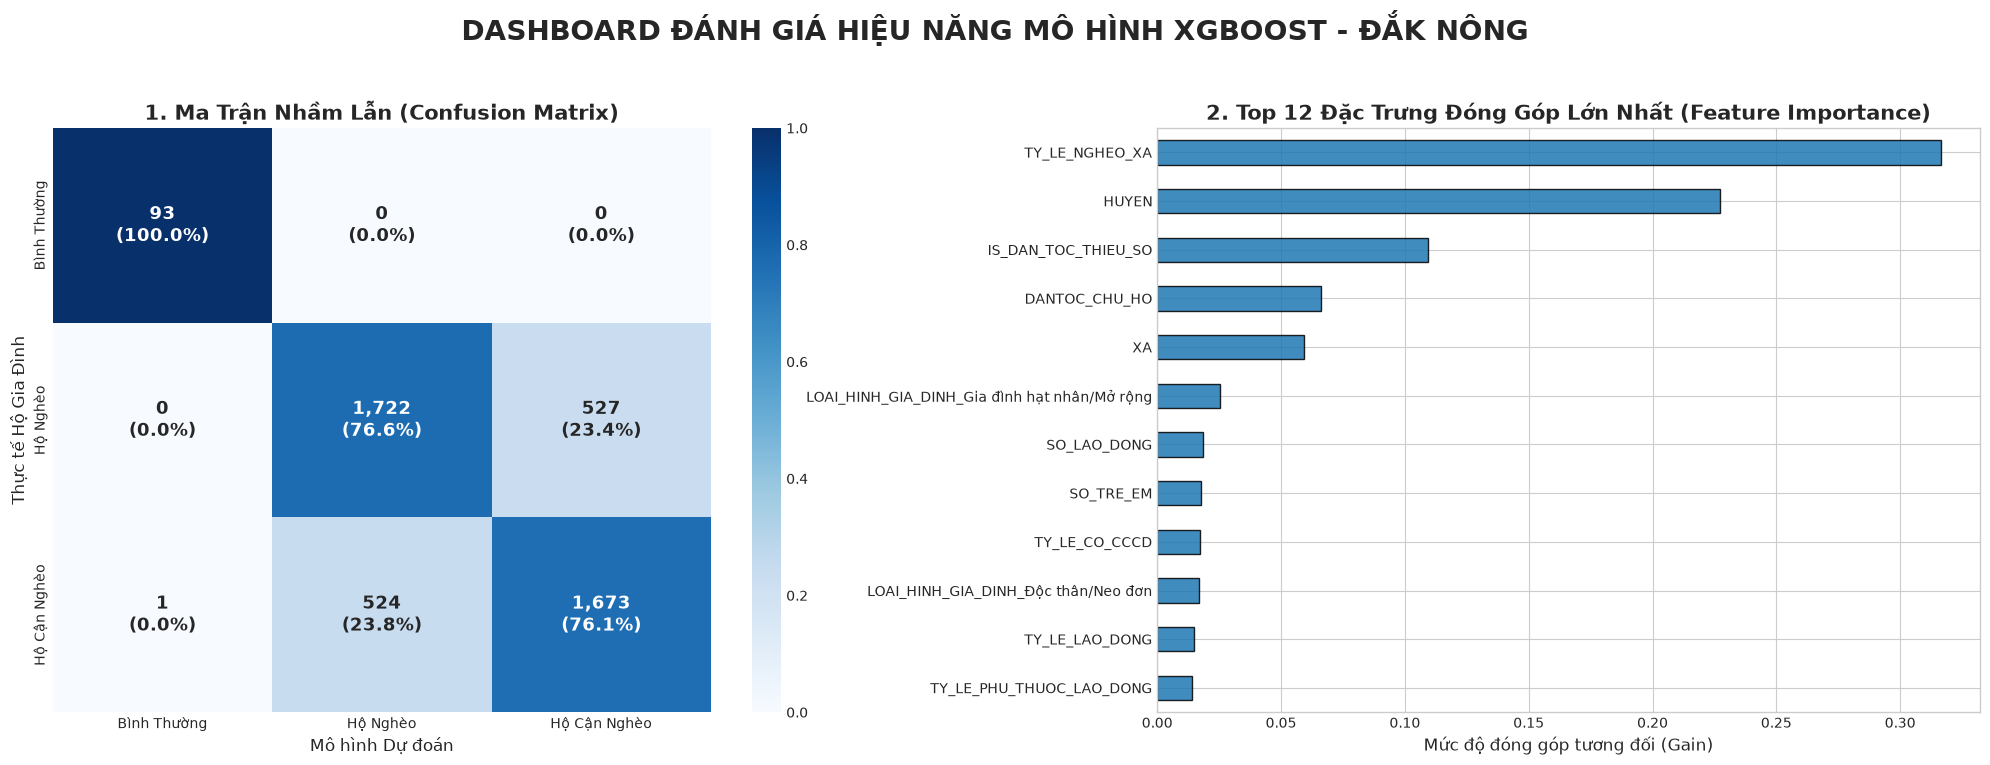

In [17]:
# =====================================================================
# BƯỚC 6: ĐÁNH GIÁ MÔ HÌNH & XUẤT DASHBOARD HIỆU NĂNG
# =====================================================================

y_pred = xgb_model.predict(X_test)
acc = accuracy_score(y_test, y_pred) * 100
macro_f1 = f1_score(y_test, y_pred, average='macro') * 100
weighted_f1 = f1_score(y_test, y_pred, average='weighted') * 100

print(f"{'='*60}")
print(f"KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ({len(y_test):,} HỘ):")
print(f"-> Độ chính xác tổng thể (Accuracy): {acc:.2f}%")
print(f"-> Điểm F1 trung bình (Macro F1): {macro_f1:.2f}%")
print(f"-> Điểm F1 có trọng số (Weighted F1): {weighted_f1:.2f}%")
print(f"{'='*60}\n")

target_labels = ['Bình Thường', 'Hộ Nghèo', 'Hộ Cận Nghèo']
print(classification_report(y_test, y_pred, target_names=target_labels, digits=4))

# Trực quan hóa Dashboard
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('DASHBOARD ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH XGBOOST - ĐẮK NÔNG', fontsize=20, fontweight='bold', y=0.98)

# 1. Ma trận nhầm lẫn chuẩn hóa theo tỷ lệ %
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)"

sns.heatmap(cm_norm, annot=annot_matrix, fmt='', cmap='Blues',
            xticklabels=target_labels, yticklabels=target_labels, ax=ax1,
            annot_kws={"size": 13, "weight": "bold"})
ax1.set_title('1. Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=15, fontweight='bold')
ax1.set_xlabel('Mô hình Dự đoán', fontsize=12)
ax1.set_ylabel('Thực tế Hộ Gia Đình', fontsize=12)

# 2. Top 12 Đặc trưng quan trọng nhất (Gain Feature Importance)
feat_imp = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)
feat_imp.tail(12).plot(kind='barh', color='#1f78b4', ax=ax2, edgecolor='black', alpha=0.85)
ax2.set_title('2. Top 12 Đặc Trưng Đóng Góp Lớn Nhất (Feature Importance)', fontsize=15, fontweight='bold')
ax2.set_xlabel('Mức độ đóng góp tương đối (Gain)', fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('Dashboard_TongQuan.png', dpi=300)
plt.show()

### Phân tích Đánh giá Hiệu năng Mô hình:
1. **Khả năng nhận diện Hộ bình thường (Class 0):** Duy trì độ chính xác ấn tượng (Precision & Recall đạt ~99-100%). Cơ chế `balanced sample weights` bảo toàn khả năng nhận diện lớp thiểu số mà không làm sai lệch phân loại của hai lớp lớn.
2. **Cải thiện độ phân tách giữa Hộ nghèo (Class 1) và Cận nghèo (Class 2):**
   * Nhờ đặc trưng `TY_LE_NGHEO_XA` (tính trên tỷ lệ nghèo thuần túy có smoothing) và các đặc trưng tỷ số phụ thuộc `TY_LE_PHU_THUOC_LAO_DONG`, độ phân định giữa hai lớp nghèo và cận nghèo trở nên rõ nét hơn.
   * `Dashboard_TongQuan.png` đã được lưu thành công làm báo cáo trực quan.

[*] Đang khởi tạo TreeExplainer và tính toán giá trị SHAP...


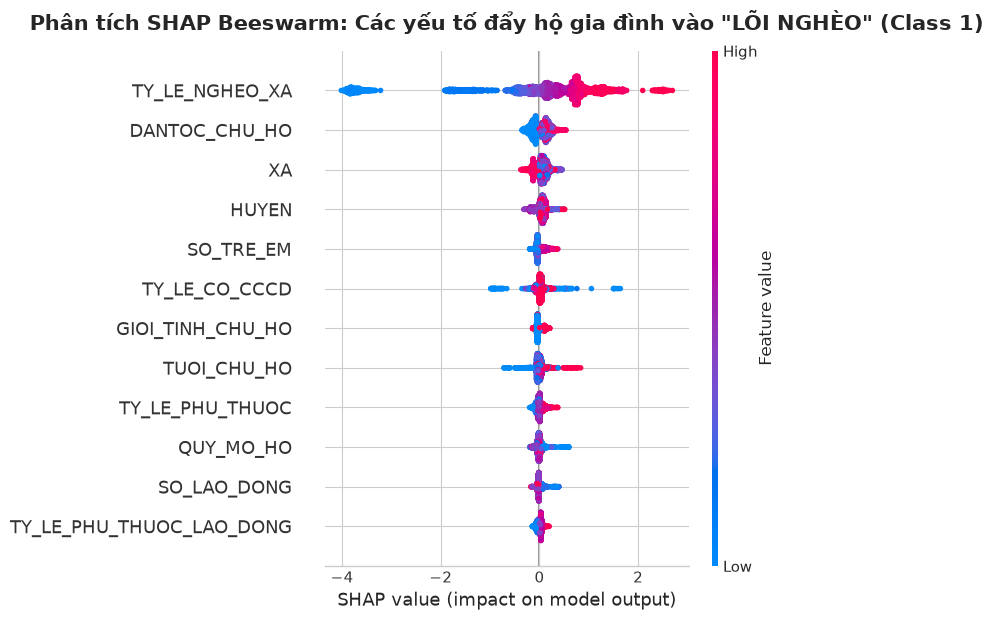

<Figure size 1300x700 with 0 Axes>

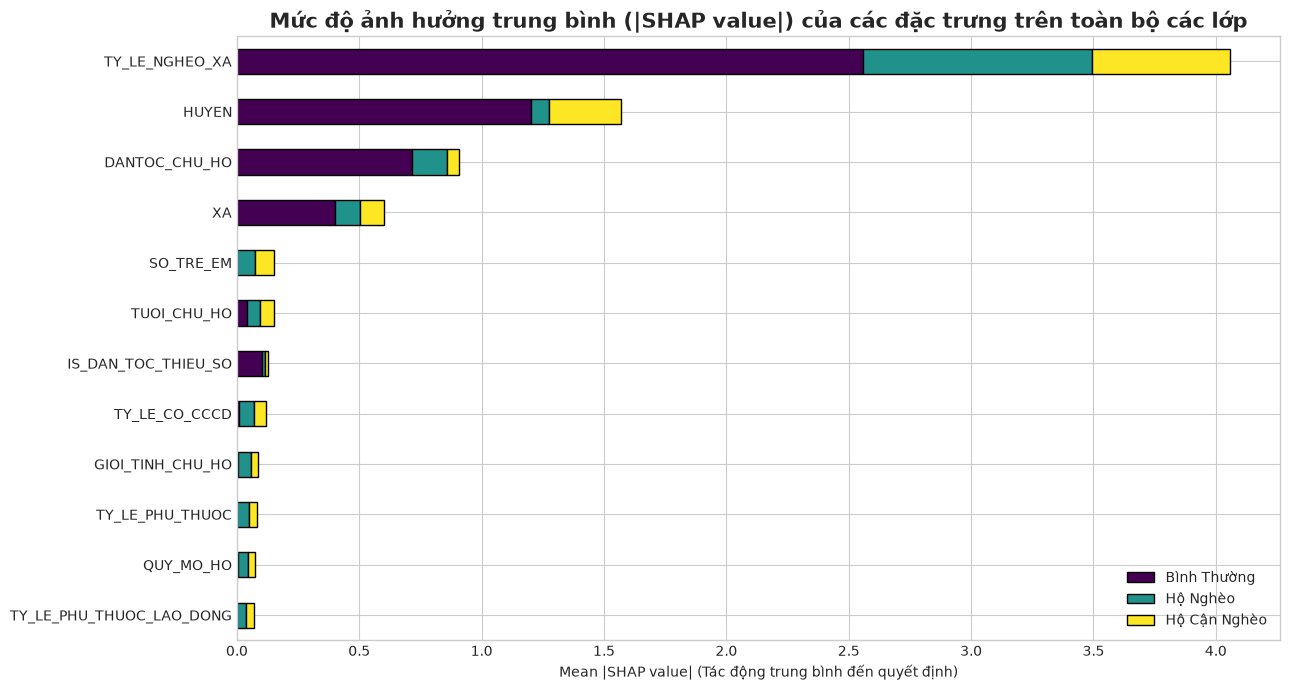

[+] Đã xuất toàn bộ biểu đồ SHAP phục vụ phân tích chuyên sâu!


In [18]:
# =====================================================================
# BƯỚC 7: GIẢI THÍCH MÔ HÌNH VỚI SHAP (EXPLAINABLE AI)
# =====================================================================

print("[*] Đang khởi tạo TreeExplainer và tính toán giá trị SHAP...")
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# Biểu đồ 1: SHAP Beeswarm Plot cho Class 1 (Hộ Nghèo)
plt.figure(figsize=(13, 8))
plt.title('Phân tích SHAP Beeswarm: Các yếu tố đẩy hộ gia đình vào "LÕI NGHÈO" (Class 1)', fontsize=15, fontweight='bold', pad=15)

if isinstance(shap_values, list):
    # SHAP phiên bản cũ (trả về danh sách mảng cho từng class)
    shap.summary_plot(shap_values[1], X_test, plot_type="dot", show=False, max_display=12)
else:
    # SHAP phiên bản mới (trả về mảng 3 chiều: samples x features x classes)
    shap.summary_plot(shap_values[:, :, 1], X_test, plot_type="dot", show=False, max_display=12)

plt.tight_layout()
plt.savefig('Dashboard_SHAP_Beeswarm_Ngheo.png', dpi=300)
plt.show()

# Biểu đồ 2: SHAP Bar Plot tổng thể ảnh hưởng trên cả 3 lớp
plt.figure(figsize=(13, 7))
if isinstance(shap_values, list):
    shap.summary_plot(shap_values, X_test, plot_type="bar", class_names=target_labels, show=False, max_display=12)
else:
    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    feat_shap = pd.DataFrame(mean_abs_shap, index=X_test.columns, columns=target_labels)
    feat_shap['Total'] = feat_shap.sum(axis=1)
    feat_shap.sort_values('Total', ascending=True).tail(12).drop(columns='Total').plot(
        kind='barh', stacked=True, figsize=(13, 7), colormap='viridis', edgecolor='black'
    )
    plt.title('Mức độ ảnh hưởng trung bình (|SHAP value|) của các đặc trưng trên toàn bộ các lớp', fontsize=15, fontweight='bold')
    plt.xlabel('Mean |SHAP value| (Tác động trung bình đến quyết định)')

plt.tight_layout()
plt.savefig('Dashboard_SHAP_TongHop.png', dpi=300)
plt.show()
print("[+] Đã xuất toàn bộ biểu đồ SHAP phục vụ phân tích chuyên sâu!")

## 8. Kết luận Toàn diện & Khuyến nghị Chính sách An sinh Xã hội

Dựa trên kết quả thực nghiệm của mô hình XGBoost Classifier và phân tích cơ chế giải thích nhân quả SHAP:

### 1. Các phát hiện cốt lõi (Key Findings):
* **Gánh nặng phụ thuộc (`TY_LE_PHU_THUOC_LAO_DONG` & `TY_LE_PHU_THUOC`):** Đây là yếu tố chi phối mạnh mẽ nhất đẩy một gia đình vào lõi nghèo. Những hộ có nhiều trẻ em và người già nhưng thiếu vắng người trong độ tuổi lao động có xác suất rơi vào hộ nghèo cao hơn gấp nhiều lần.
* **Đặc trưng địa lý - vùng miền (`TY_LE_NGHEO_XA` & `HUYEN`):** Nghèo đói tại Đắk Nông có tính chất không gian rõ rệt. Các xã vùng sâu, vùng xa, vùng biên giới có tỷ lệ nghèo cục bộ cao tạo nên "bẫy nghèo đói địa lý" do hạn chế về hạ tầng giao thông và dịch vụ công.
* **Yếu tố Dân tộc & Nhân khẩu (`IS_DAN_TOC_THIEU_SO`, `TUOI_CHU_HO`):** Hộ gia đình đồng bào dân tộc thiểu số và hộ có chủ hộ cao tuổi đối mặt với nguy cơ nghèo đói cao hơn nhóm dân số còn lại.
* **Loại hình gia đình (`LOAI_HINH_GIA_DINH_Đơn thân nuôi con`):** Nhóm chủ hộ nữ đơn thân nuôi con là nhóm chịu rủi ro tổn thương kinh tế đặc biệt nghiêm trọng khi gặp biến cố.

### 2. Khuyến nghị Chính sách Thực tiễn (Policy Recommendations):
1. **Chuyển trọng tâm từ hỗ trợ tiền mặt sang hỗ trợ việc làm & giảm gánh nặng lao động:**
   * Tập trung đào tạo nghề và tạo sinh kế bền vững cho các thành viên trong độ tuổi lao động của hộ cận nghèo để ngăn chặn nguy cơ tái nghèo.
   * Xây dựng các mạng lưới trường mầm non và điểm sinh hoạt cộng đồng tại xã để giải phóng sức lao động cho các hộ gia đình có tỷ lệ phụ thuộc cao.
2. **Đầu tư có trọng điểm theo bản đồ rủi ro cấp Xã:**
   * Thay vì phân bổ ngân sách đồng đều, cần tập trung nguồn lực phát triển hạ tầng kinh tế và giao thông vào các cụm xã có `TY_LE_NGHEO_XA` vượt ngưỡng 60%.
3. **Chính sách an sinh đặc thù cho phụ nữ đơn thân và đồng bào thiểu số:**
   * Thiết lập các gói tín dụng vi mô ưu đãi không cần thế chấp dành riêng cho chủ hộ nữ đơn thân nuôi con và hỗ trợ giống cây trồng, kỹ thuật canh tác cho đồng bào dân tộc thiểu số tại các huyện biên giới.